# Medical Insurance Cost Prediction — Regression Models
Using `insurance_cleaned.csv` to train and compare **5 regression algorithms**.

**Pipeline:**
1. Load & inspect cleaned data
2. Feature extraction & engineering
3. Encode categorical features
4. Train/test split & scaling
5. Train 5 regression models
6. Evaluate: MAE, RMSE, R² Score
7. Model comparison visualizations

## Step 1 — Import Libraries & Load Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

df = pd.read_csv('../data_cleaning/insurance_cleaned.csv')
print('Dataset shape:', df.shape)
print('Columns:', list(df.columns))
df.head(10)

Dataset shape: (1337, 7)
Columns: ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
5,31,female,25.740,0,no,southeast,3756.62160
6,46,female,33.440,1,no,southeast,8240.58960
7,37,female,27.740,3,no,northwest,7281.50560
8,37,male,29.830,2,no,northeast,6406.41070
9,60,female,25.840,0,no,northwest,28923.13692


## Step 2 — Feature Extraction & Engineering

**Features extracted from EDA (data_visualization.ipynb):**

| Feature | Type | Importance |
| --- | --- | --- |
| `smoker` | Categorical | Very High — primary cost driver (~3.8x difference) |
| `obese_smoker` | Engineered | High — obese smokers average \$41,558 vs \$21,363 for non-obese smokers |
| `age` | Numeric | High — correlation r = 0.30 |
| `bmi` | Numeric | Moderate — correlation r = 0.20 |
| `region` | Categorical | Low — southeast highest at \$14,735 avg |
| `sex` | Categorical | Low — slight male premium |
| `children` | Numeric | Very Low — correlation r = 0.07 |

In [2]:
# Create interaction feature: obese + smoker -> very high risk group
df['obese_smoker'] = ((df['bmi'] >= 30) & (df['smoker'] == 'yes')).astype(int)

print('Obese-smoker count:', df['obese_smoker'].sum())
print('Mean charges by obese_smoker group:')
print(df.groupby('obese_smoker')['charges'].mean().round(2))

Obese-smoker count: 145
Mean charges by obese_smoker group:
obese_smoker
0     9839.16
1    41557.99
Name: charges, dtype: float64


## Step 3 — Encode Categorical Features

In [3]:
df_encoded = pd.get_dummies(df, drop_first=True, dtype=int)

X = df_encoded.drop('charges', axis=1)
y = df_encoded['charges']

print('Final features:', list(X.columns))
print('Feature matrix shape:', X.shape)
X.head()

Final features: ['age', 'bmi', 'children', 'obese_smoker', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']
Feature matrix shape: (1337, 9)


,age,bmi,children,obese_smoker,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,0,0,1,0,0,1
1,18,33.770,1,0,1,0,0,1,0
2,28,33.000,3,0,1,0,0,1,0
3,33,22.705,0,0,1,0,1,0,0
4,32,28.880,0,0,1,0,1,0,0


## Step 4 — Train / Test Split & Feature Scaling

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Scale features for linear models (Linear Regression & Ridge)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

print('Training samples:', X_train.shape[0])
print('Test samples:    ', X_test.shape[0])

Training samples: 1069
Test samples:     268


## Step 5 — Train All 5 Regression Models
Models trained:
1. **Linear Regression**
2. **Decision Tree Regressor**
3. **Random Forest Regressor**
4. **Gradient Boosting Regressor**
5. **Ridge Regression**

In [5]:
# (name, model_object, use_scaled_data)
models = [
    ('Linear Regression',           LinearRegression(),                     True),
    ('Decision Tree Regressor',     DecisionTreeRegressor(random_state=42), False),
    ('Random Forest Regressor',     RandomForestRegressor(random_state=42), False),
    ('Gradient Boosting Regressor', GradientBoostingRegressor(random_state=42), False),
    ('Ridge Regression',            Ridge(alpha=1.0),                       True),
]

results = []
for name, model, use_scaled in models:
    if use_scaled:
        model.fit(X_train_sc, y_train)
        preds = model.predict(X_test_sc)
    else:
        model.fit(X_train, y_train)
        preds = model.predict(X_test)

    results.append({
        'Model':    name,
        'MAE':      round(mean_absolute_error(y_test, preds), 2),
        'RMSE':     round(root_mean_squared_error(y_test, preds), 2),
        'R2 Score': round(r2_score(y_test, preds), 4),
    })
    print(f'{name:35s} -> MAE={results[-1]["MAE"]:>10,.2f}  RMSE={results[-1]["RMSE"]:>10,.2f}  R2={results[-1]["R2 Score"]:.4f}')

print('\nAll models trained successfully.')

Linear Regression                   -> MAE=  2,391.56  RMSE=  4,163.41  R2=0.9057
Decision Tree Regressor             -> MAE=  2,843.50  RMSE=  6,098.73  R2=0.7976


Random Forest Regressor             -> MAE=  2,612.97  RMSE=  4,681.71  R2=0.8807
Gradient Boosting Regressor         -> MAE=  2,463.40  RMSE=  4,217.58  R2=0.9032
Ridge Regression                    -> MAE=  2,392.82  RMSE=  4,164.45  R2=0.9056

All models trained successfully.


## Step 6 — Evaluation Metrics Table

In [6]:
results_df = pd.DataFrame(results).sort_values('R2 Score', ascending=False).reset_index(drop=True)
results_df.index += 1   # rank starts at 1
results_df

,Model,MAE,RMSE,R2 Score
1,Linear Regression,2391.56,4163.41,0.9057
2,Ridge Regression,2392.82,4164.45,0.9056
3,Gradient Boosting Regressor,2463.40,4217.58,0.9032
4,Random Forest Regressor,2612.97,4681.71,0.8807
5,Decision Tree Regressor,2843.50,6098.73,0.7976


## Step 7 — Model Comparison Visualizations
### Chart 1: R² Score (Higher is Better)

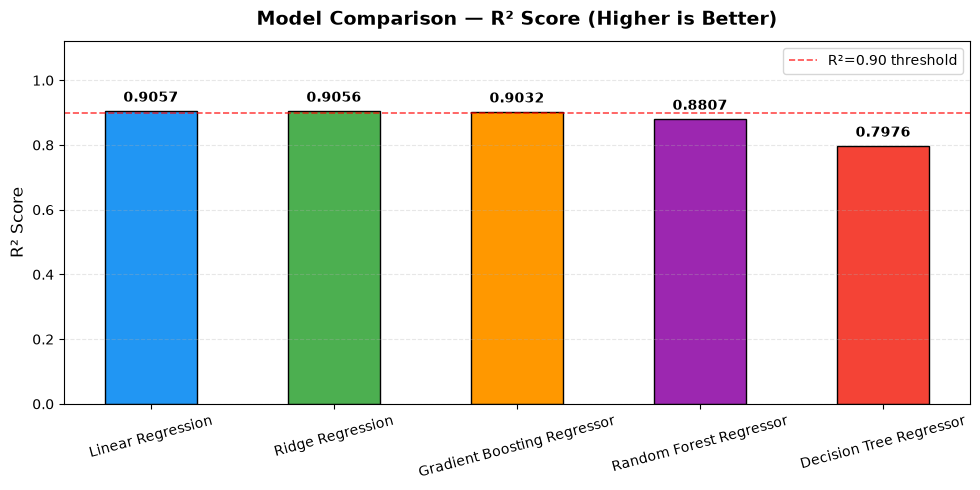

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
colors = ['#2196F3', '#4CAF50', '#FF9800', '#9C27B0', '#F44336']
bars = ax.bar(results_df['Model'], results_df['R2 Score'], color=colors, edgecolor='black', width=0.5)
ax.set_title('Model Comparison — R² Score (Higher is Better)', fontsize=14, fontweight='bold', pad=12)
ax.set_ylabel('R² Score', fontsize=12)
ax.set_ylim(0, 1.12)
ax.tick_params(axis='x', rotation=15)
ax.grid(axis='y', alpha=0.3, linestyle='--')
ax.axhline(y=0.9, color='red', linestyle='--', linewidth=1.2, alpha=0.7, label='R²=0.90 threshold')
ax.legend(fontsize=10)
for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, h + 0.018,
            f'{h:.4f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()

### Chart 2: MAE — Mean Absolute Error (Lower is Better)

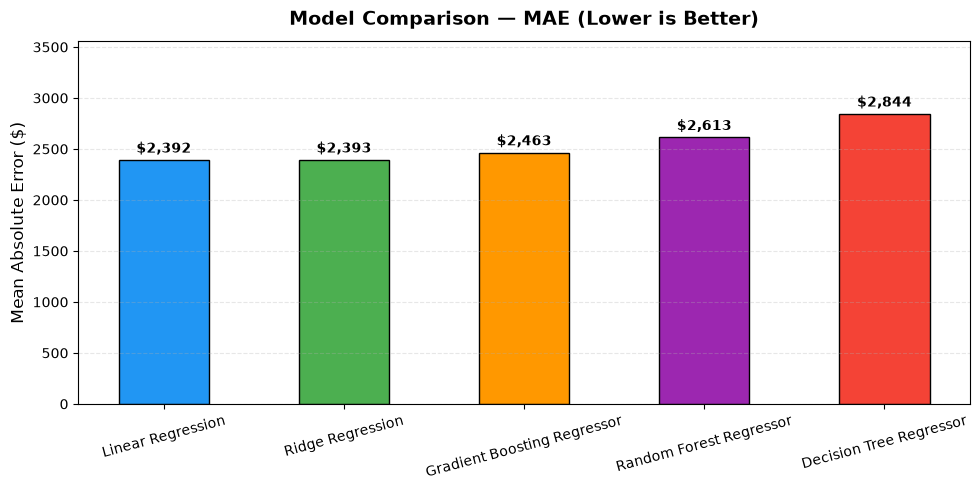

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
colors_mae = ['#2196F3', '#4CAF50', '#FF9800', '#9C27B0', '#F44336']
bars = ax.bar(results_df['Model'], results_df['MAE'], color=colors_mae, edgecolor='black', width=0.5)
ax.set_title('Model Comparison — MAE (Lower is Better)', fontsize=14, fontweight='bold', pad=12)
ax.set_ylabel('Mean Absolute Error ($)', fontsize=12)
ax.set_ylim(0, results_df['MAE'].max() * 1.25)
ax.tick_params(axis='x', rotation=15)
ax.grid(axis='y', alpha=0.3, linestyle='--')
for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, h + 40,
            f'${h:,.0f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()

### Chart 3: RMSE — Root Mean Squared Error (Lower is Better)

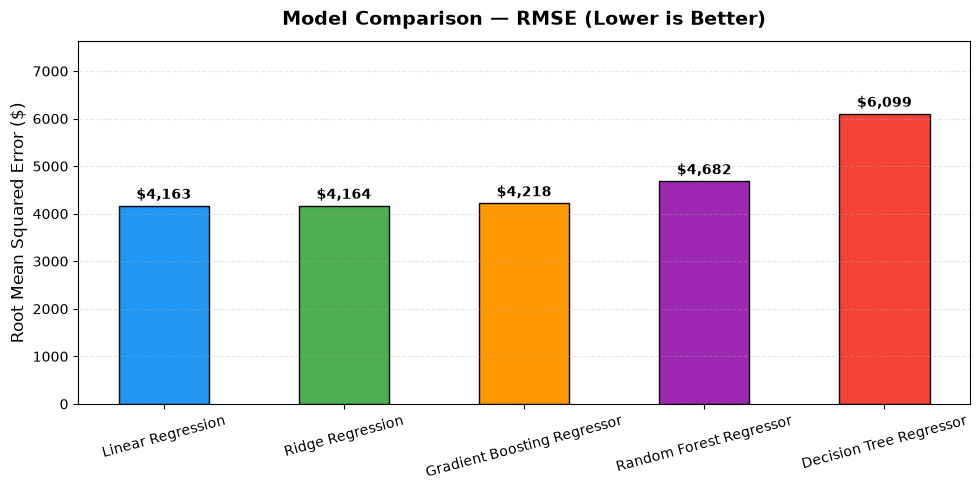

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
colors_rmse = ['#2196F3', '#4CAF50', '#FF9800', '#9C27B0', '#F44336']
bars = ax.bar(results_df['Model'], results_df['RMSE'], color=colors_rmse, edgecolor='black', width=0.5)
ax.set_title('Model Comparison — RMSE (Lower is Better)', fontsize=14, fontweight='bold', pad=12)
ax.set_ylabel('Root Mean Squared Error ($)', fontsize=12)
ax.set_ylim(0, results_df['RMSE'].max() * 1.25)
ax.tick_params(axis='x', rotation=15)
ax.grid(axis='y', alpha=0.3, linestyle='--')
for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, h + 80,
            f'${h:,.0f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()

### Chart 4: Side-by-Side — All 3 Metrics Combined

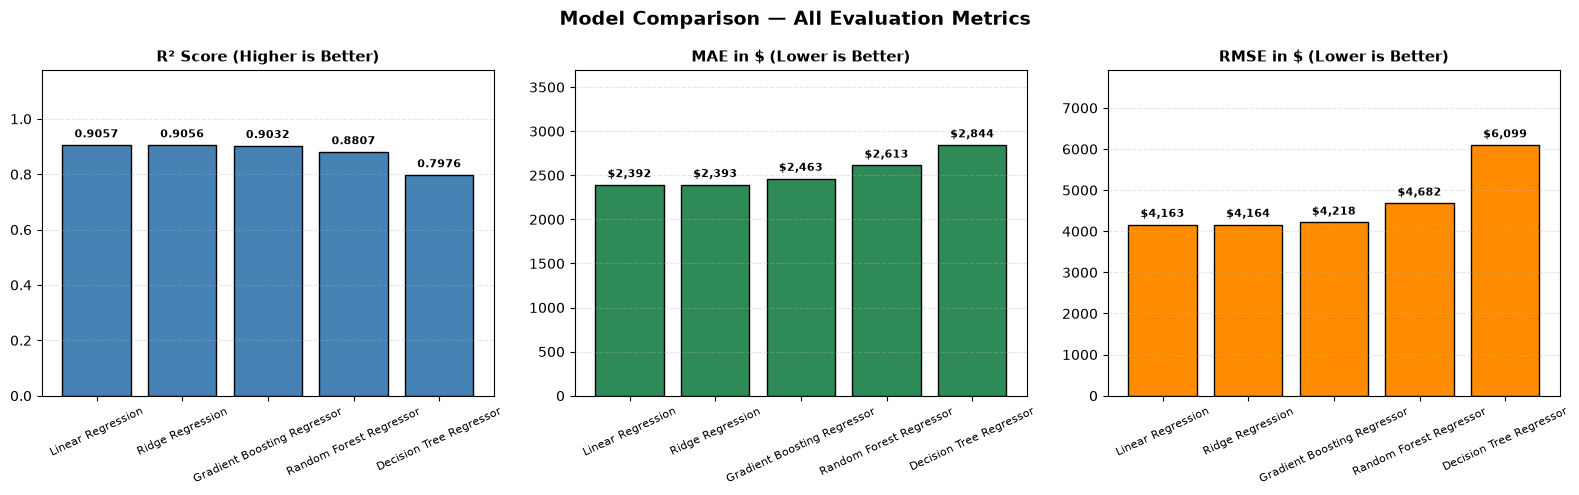

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Model Comparison — All Evaluation Metrics', fontsize=14, fontweight='bold')

metric_info = [
    ('R2 Score', 'R² Score (Higher is Better)', 'steelblue',  None),
    ('MAE',      'MAE in $ (Lower is Better)',  'seagreen',   '$'),
    ('RMSE',     'RMSE in $ (Lower is Better)', 'darkorange', '$'),
]

for ax, (col, title, color, prefix) in zip(axes, metric_info):
    b = ax.bar(results_df['Model'], results_df[col], color=color, edgecolor='black')
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_ylim(0, results_df[col].max() * 1.3)
    ax.tick_params(axis='x', rotation=25, labelsize=8)
    ax.grid(axis='y', alpha=0.3, linestyle='--')
    for bar in b:
        h = bar.get_height()
        label = f'{prefix}{h:,.0f}' if prefix else f'{h:.4f}'
        ax.text(bar.get_x() + bar.get_width() / 2, h + results_df[col].max() * 0.02,
                label, ha='center', va='bottom', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.show()

## Step 8 — Feature Importances (Gradient Boosting)

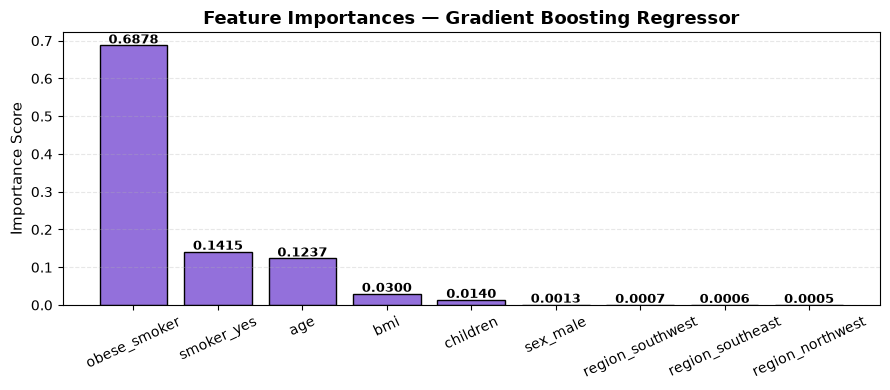


Feature Importances (Gradient Boosting):
obese_smoker        0.6878
smoker_yes          0.1415
age                 0.1237
bmi                 0.0300
children            0.0140
sex_male            0.0013
region_southwest    0.0007
region_southeast    0.0006
region_northwest    0.0005


In [11]:
gb_model = models[3][1]  # Gradient Boosting Regressor
importances = pd.Series(gb_model.feature_importances_, index=X.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(importances.index, importances.values, color='mediumpurple', edgecolor='black')
ax.set_title('Feature Importances — Gradient Boosting Regressor', fontsize=13, fontweight='bold')
ax.set_ylabel('Importance Score', fontsize=11)
ax.tick_params(axis='x', rotation=25)
ax.grid(axis='y', alpha=0.3, linestyle='--')
for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, h + 0.005,
            f'{h:.4f}', ha='center', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.show()

print('\nFeature Importances (Gradient Boosting):')
print(importances.round(4).to_string())

## Conclusion

**Model Ranking (by R² Score):**

| Rank | Model | MAE | RMSE | R² Score |
| --- | --- | ---: | ---: | ---: |
| 1 | **Linear Regression** | \$2,391.56 | \$4,163.41 | **0.9057** |
| 2 | **Ridge Regression** | \$2,392.82 | \$4,164.45 | **0.9056** |
| 3 | **Gradient Boosting Regressor** | \$2,463.40 | \$4,217.58 | **0.9032** |
| 4 | **Random Forest Regressor** | \$2,612.97 | \$4,681.71 | **0.8807** |
| 5 | **Decision Tree Regressor** | \$2,843.50 | \$6,098.73 | **0.7976** |

**Key Insights:**
- **Best Model:** Linear Regression (R² = 0.9057) — explains 90.6% of cost variance.
- **Why linear models win:** The engineered `obese_smoker` feature linearises the dominant non-linear interaction between BMI and smoking status.
- **Top 3 features** (Gradient Boosting): `obese_smoker` (68.78%), `smoker_yes` (14.15%), `age` (12.37%) — together account for **95.3%** of predictive power.
- **Decision Tree** overfits without pruning, giving the worst generalisation (R² = 0.7976).

## Step 9 ? Save Best Model with Joblib

The **best model** is **Linear Regression** (R? = 0.9057).

Both the trained model and the `StandardScaler` are saved so the pipeline can be fully reconstructed for inference without retraining.

In [12]:
import joblib
import os

# Best model: Linear Regression (R2 = 0.9057)
best_model = models[0][1]   # LinearRegression already fitted above
best_model_name = models[0][0]

# Save the model
os.makedirs('saved_models', exist_ok=True)

joblib.dump(best_model, 'saved_models/linear_regression_best_model.pkl')
joblib.dump(scaler,     'saved_models/scaler.pkl')

print(f'Best model saved  : saved_models/linear_regression_best_model.pkl')
print(f'Scaler saved      : saved_models/scaler.pkl')
print(f'Model name        : {best_model_name}')
print(f'Model R2 Score    : {results_df[results_df["Model"] == best_model_name]["R2 Score"].values[0]}')

# Quick verification ? reload and predict
loaded_model  = joblib.load('saved_models/linear_regression_best_model.pkl')
loaded_scaler = joblib.load('saved_models/scaler.pkl')

X_test_check = loaded_scaler.transform(X_test)
preds_check  = loaded_model.predict(X_test_check)

from sklearn.metrics import r2_score
print(f'\nVerification ? R2 after reload: {r2_score(y_test, preds_check):.4f}  (should match original)')

Best model saved  : saved_models/linear_regression_best_model.pkl
Scaler saved      : saved_models/scaler.pkl
Model name        : Linear Regression
Model R2 Score    : 0.9057

Verification ? R2 after reload: 0.9057  (should match original)
